# Sequential experiments on running counts

Lindon & Malek (2022), *Anytime-Valid Inference for Multinomial Count Data* (NeurIPS), build a
sequential test for experiments whose outcomes are counts: conversions, errors, sign-ups. Their test
statistic is a Dirichlet–multinomial Bayes factor, and the thing to notice is what it depends on.
With $\boldsymbol\theta_0$ the null allocation, $\boldsymbol\alpha_0$ a Dirichlet mixing distribution, and
$\mathbf S_n$ the vector of running counts per arm after $n$ events (their Eq. 3):

$$BF_{10}(\mathbf x_{1:n}) = \frac{\mathrm{B}(\boldsymbol\alpha_0 + \mathbf S_n)}{\mathrm B(\boldsymbol\alpha_0)}\,
\frac{1}{\boldsymbol\theta_0^{\mathbf S_n}}.$$

The whole event stream enters only through $\mathbf S_n$. Two consequences:

1. **Monitoring is cheap.** Updating the test is an increment of one count.
2. **Nuisance time-variation drops out.** If each arm's events arrive as a Poisson process with
   intensity $\rho_a\,\lambda(t)$, where $\lambda(t)$ is an arbitrary shared baseline (weekday cycles,
   marketing pushes), then conditional on an event happening, the arm it came from is
   $\text{Multinomial}(1, \boldsymbol\theta)$ with $\theta_a \propto \rho_a$. The unknown $\lambda(t)$
   cancels. We never model it.

In [1]:
import time
import numpy as np
import pandas as pd
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy.special import gammaln
from scipy import stats

rng = np.random.default_rng(202)
SAMPLE_KW = dict(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=False)


def timed_fit(model, label, n_rows, **kw):
    t0 = time.perf_counter()
    idata = pm.sample(model=model, random_seed=rng, **{**SAMPLE_KW, **kw})
    secs = time.perf_counter() - t0
    ess = float(az.summary(idata)["ess_bulk"].min())
    return idata, {"model": label, "rows in likelihood": n_rows, "wall time (s)": round(secs, 1),
                   "min ESS/s": round(ess / secs, 1)}

## A three-arm conversion test with a wandering baseline

Two weeks of hourly traffic. The shared baseline has a daily cycle and a mid-test promotion that
triples volume for two days. Arm C converts 6% more than control; arm B is identical to control.
Traffic is split equally, so $\boldsymbol\theta_0 = (1/3, 1/3, 1/3)$.

In [2]:
hours = np.arange(24 * 14)
baseline = 80 * (1 + 0.7 * np.sin(2 * np.pi * (hours - 6) / 24))
baseline[(hours >= 24 * 6) & (hours < 24 * 8)] *= 3            # the promotion
rho = np.array([1.00, 1.00, 1.06])                              # control, B, C
theta0 = np.ones(3) / 3

hourly = rng.poisson(baseline[:, None] * rho[None, :])          # (hour, arm) event counts
# expand to an event stream: the arm label of every conversion, shuffled within the hour
events = np.concatenate([rng.permutation(np.repeat(np.arange(3), h)) for h in hourly])
S = np.cumsum(np.eye(3, dtype=int)[events], axis=0)            # running counts S_n, shape (n, 3)
print(f"{len(events):,} conversions; final counts {S[-1]}")

106,072 conversions; final counts [34889 34485 36698]


The Bayes factor, as a function of the running counts only. With a uniform mixing distribution
$\boldsymbol\alpha_0 = \mathbf 1$ (the paper's default). The sequential $p$-value is
$p_n = \min(p_{n-1}, 1/BF_n)$, and rejecting when $p_n \le u$ has type-I error at most $u$ under
continuous monitoring.

In [3]:
def log_mbeta(a):
    return gammaln(a).sum(-1) - gammaln(a.sum(-1))


def log_bf(S, theta0, alpha0):
    return log_mbeta(alpha0 + S) - log_mbeta(alpha0) - (S * np.log(theta0)).sum(-1)


alpha0 = np.ones(3)
logbf = log_bf(S, theta0, alpha0)
p_seq = np.minimum.accumulate(np.minimum(1, np.exp(-logbf)))

u = 0.05
stop = int(np.argmax(p_seq <= u)) if (p_seq <= u).any() else None
print("rejected at event", stop, "of", len(events))

rejected at event 24320 of 106072


The sufficiency claim, checked: the recursive product of per-event predictive bets (their Eq. 5,
which walks through every event in order) reproduces the closed form that only uses $\mathbf S_n$.

In [4]:
prev = np.vstack([np.zeros(3, int), S[:-1]])                    # S_{n-1}
post_mean = (alpha0 + prev) / (alpha0.sum() + np.arange(len(events)))[:, None]
recursive = np.cumsum(np.log(post_mean[np.arange(len(events)), events] / theta0[events]))
print("max |recursive - closed form| =", np.abs(recursive - logbf).max())

max |recursive - closed form| = 5.707825323497673e-10


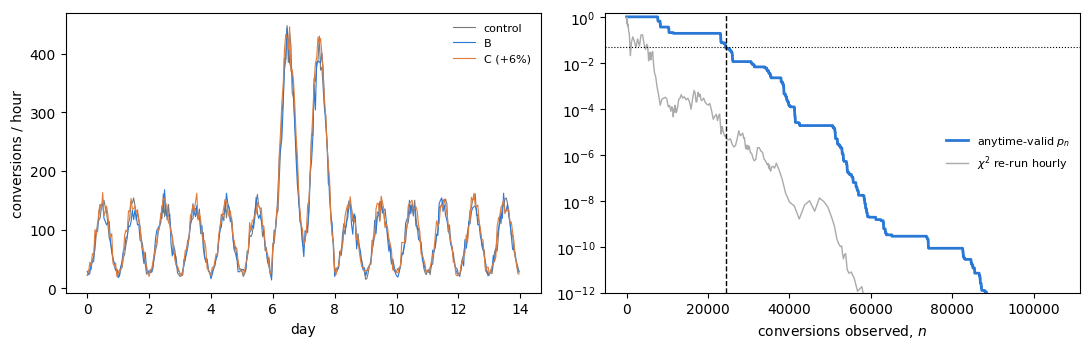

In [5]:
#| label: fig-seq-path
#| fig-cap: "Left: hourly conversions per arm; the baseline is anything but stationary. Right: the anytime-valid sequential p-value computed from running counts, rejecting at the dashed line. A naive chi-square test re-run after every hour is shown for contrast."
cum_hourly = np.cumsum(hourly, axis=0)
chi_p = np.array([stats.chisquare(c).pvalue for c in cum_hourly])
n_at_hour = cum_hourly.sum(1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
for a, (name, col) in enumerate(zip(["control", "B", "C (+6%)"], ["#7a7a7a", "#2a78d6", "#e07b39"])):
    ax.plot(hours / 24, hourly[:, a], lw=0.8, color=col, label=name)
ax.set_xlabel("day")
ax.set_ylabel("conversions / hour")
ax.legend(frameon=False, fontsize=8)
ax = axes[1]
ax.plot(np.arange(1, len(events) + 1), p_seq, color="#2a78d6", lw=2, label="anytime-valid $p_n$")
ax.plot(n_at_hour, chi_p, color="#aaaaaa", lw=1, label=r"$\chi^2$ re-run hourly")
ax.axhline(u, color="k", lw=0.8, ls=":")
if stop is not None:
    ax.axvline(stop, color="k", lw=1, ls="--")
ax.set_yscale("log")
ax.set_ylim(1e-12, 1.5)
ax.set_xlabel("conversions observed, $n$")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

## Type-I error under continuous monitoring

Because the statistic is a function of $\mathbf S_n$, simulating thousands of A/A experiments with
continuous monitoring is just a cumulative sum. Peek after every event with the anytime-valid
$p$-value, and after every 250 events with a fixed-$n$ chi-square, and record whether either ever
crosses 0.05.

In [6]:
n_sims, n_events = 1000, 10_000
null_events = rng.integers(0, 3, size=(n_sims, n_events))
S_null = np.cumsum(np.eye(3, dtype=np.int32)[null_events], axis=1)            # (sim, n, 3)
ever_bf = (log_bf(S_null, theta0, alpha0) >= np.log(1 / u)).any(axis=1).mean()
peeks = S_null[:, 249::250, :]
expected = peeks.sum(-1, keepdims=True) / 3
chi = ((peeks - expected) ** 2 / expected).sum(-1)
ever_chi = (stats.chi2.sf(chi, df=2) <= u).any(axis=1).mean()
pd.DataFrame({"procedure": ["anytime-valid BF on S_n (every event)", "chi-square (every 250 events)"],
              "P(ever reject | null)": [ever_bf, ever_chi]})

,procedure,P(ever reject | null)
0,anytime-valid BF on S_n (every event),0.038
1,chi-square (every 250 events),0.312


## Estimation in PyMC: one categorical per event vs one multinomial

For estimation we want the posterior for $\boldsymbol\theta$, and from it the rate ratios
$\rho_a/\rho_{\text{control}} = (\theta_a/\theta_{0,a})/(\theta_{\text{ctrl}}/\theta_{0,\text{ctrl}})$.
The raw-data model is a categorical likelihood over every event; the compressed one is a single
multinomial on $\mathbf S_n$. The conjugate answer $\text{Dirichlet}(\boldsymbol\alpha_0 + \mathbf S_n)$
is available too.

In [7]:
coords = {"arm": ["control", "B", "C"]}
n_final = S[-1]


def add_ratios(theta):
    ratio = (theta / theta0) / (theta[0] / theta0[0])
    pm.Deterministic("rate_ratio", ratio, dims="arm")


with pm.Model(coords=coords) as cat_full:
    theta = pm.Dirichlet("theta", a=alpha0, dims="arm")
    add_ratios(theta)
    pm.Categorical("arm_of_event", p=theta, observed=events)

with pm.Model(coords=coords) as mult_suff:
    theta = pm.Dirichlet("theta", a=alpha0, dims="arm")
    add_ratios(theta)
    pm.Multinomial("S_n", n=n_final.sum(), p=theta, observed=n_final)

idata_full, rec_full = timed_fit(cat_full, "Categorical, every event", len(events))
idata_suff, rec_suff = timed_fit(mult_suff, "Multinomial, S_n", 1)

exact = rng.dirichlet(alpha0 + n_final, 20_000)
exact_ratio_C = (exact[:, 2] / theta0[2]) / (exact[:, 0] / theta0[0])

NUTS[nutpie]: [theta]
NUTS[nutpie]: [theta]


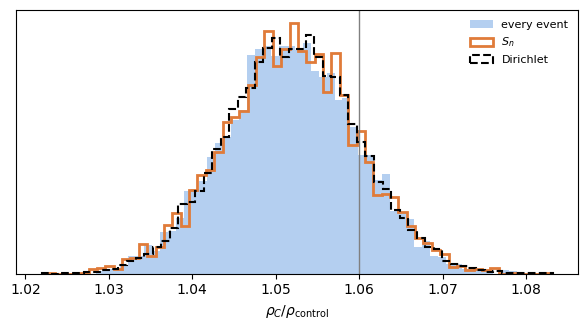

In [8]:
#| label: fig-seq-equiv
#| fig-cap: "Posterior rate ratio of arm C to control: every event (filled), running counts (line), conjugate Dirichlet (dashed)."
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.hist(idata_full.posterior["rate_ratio"].sel(arm="C").values.ravel(), bins=60, density=True,
        alpha=0.35, color="#2a78d6", label="every event")
ax.hist(idata_suff.posterior["rate_ratio"].sel(arm="C").values.ravel(), bins=60, density=True,
        histtype="step", lw=2, color="#e07b39", label="$S_n$")
ax.hist(exact_ratio_C, bins=60, density=True, histtype="step", lw=1.5, ls="--", color="k", label="Dirichlet")
ax.axvline(rho[2], color="grey", lw=1)
ax.set_yticks([])
ax.set_xlabel(r"$\rho_C / \rho_{\text{control}}$")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
#| label: tbl-seq-speed
#| tbl-cap: "Same posterior, very different cost."
speed = pd.DataFrame([rec_full, rec_suff])
speed["posterior mean ratio C"] = [float(i.posterior["rate_ratio"].sel(arm="C").mean()) for i in (idata_full, idata_suff)]
speed.round(4)

,model,rows in likelihood,wall time (s),min ESS/s,posterior mean ratio C
0,"Categorical, every event",106072,5.5,384.8,1.0518
1,"Multinomial, S_n",1,0.9,2220.7,1.0518


## What you give up

- **The time series.** Conditioning on events throws away *when* they happened, which is exactly
  why $\lambda(t)$ vanishes. If you want to know whether the effect itself changed during the
  promotion, the counts cannot tell you; you need $\mathbf S$ per period.
- **The guarantee is frequentist and does not depend on $\boldsymbol\alpha_0$** (the paper is explicit
  about this), but power and expected stopping time do. A Dirichlet concentrated near
  $\boldsymbol\theta_0$ finds small effects faster and large effects slower.